In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df=pd.read_csv("../data/WA_Fn-UseC_-Telco-Customer-Churn.csv")

print(df.head(2))
print(df.shape)
# print(df.info())
print(df.describe())
print("Uinique customers:", df["customerID"].nunique())

   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   

  TechSupport StreamingTV StreamingMovies        Contract PaperlessBilling  \
0          No          No              No  Month-to-month              Yes   
1          No          No              No        One year               No   

      PaymentMethod MonthlyCharges  TotalCharges Churn  
0  Electronic check          29.85         29.85    No  
1      Mailed check          56.95        1889.5    No  

[2 rows x 21 columns]
(7043, 21)
       SeniorCitizen       tenure  MonthlyCharges
count    7043.000000  7043.000000     70

Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


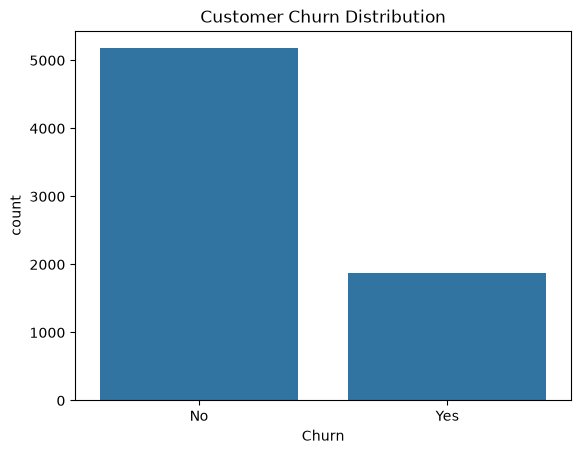

In [4]:
print(df['Churn'].value_counts())
print(df['Churn'].value_counts(normalize=True)*100)


sns.countplot(data=df,x="Churn")

plt.title("Customer Churn Distribution")
plt.show()

In [5]:
df["TotalCharges"]=pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

df.isnull().sum()

df = df.dropna(subset=["TotalCharges"])
print(df["TotalCharges"].isnull().sum())


0


In [6]:
pd.crosstab(df["Contract"],df["Churn"],normalize="index")*100

Churn,No,Yes
Contract,,
Month-to-month,57.290323,42.709677
One year,88.722826,11.277174
Two year,97.151335,2.848665


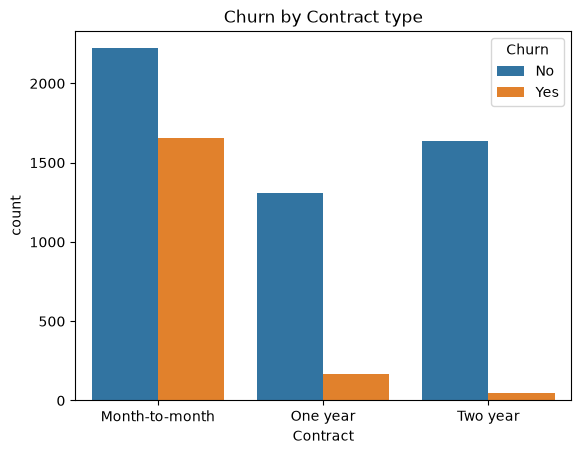

In [7]:
sns.countplot(
    data=df,
    x="Contract",
    hue="Churn"
)

plt.title("Churn by Contract type")

plt.show()



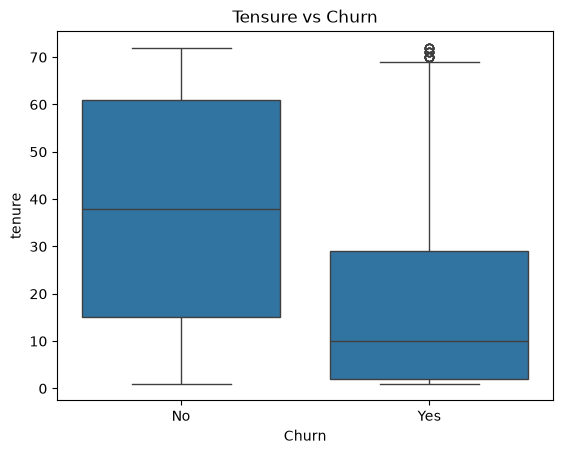

Churn
No     37.650010
Yes    17.979133
Name: tenure, dtype: float64


In [8]:
sns.boxplot(
    data=df,
    x="Churn",
    y="tenure"
)

plt.title("Tensure vs Churn")
plt.show()

print(df.groupby("Churn")["tenure"].mean())

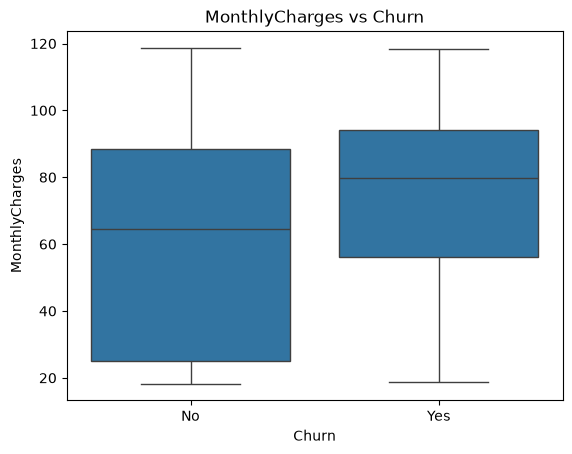

Churn
No     61.307408
Yes    74.441332
Name: MonthlyCharges, dtype: float64


In [9]:
sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("MonthlyCharges vs Churn")
plt.show()

print(df.groupby("Churn")["MonthlyCharges"].mean())

In [10]:
print(f"1. Dataset size: {df.shape[0]} rows")
print(f"2. Number of features: {df.shape[1]} columns")
print(f"3. Missing values: {df.isnull().sum().sum()}")
print(f"4. Duplicate rows: {df.duplicated().sum()}")

churn_pct = df['Churn'].value_counts(normalize=True) * 100
print(f"5. Churn Yes %: {churn_pct['Yes']:.2f}%")
print(f"6. Churn No %: {churn_pct['No']:.2f}%")


highest_churn_contract=df[df['Churn']=='Yes']["Contract"].value_counts().index[0]
print(f"7. Which contract has the highest churn?: {highest_churn_contract}")


avg_tenure=df.groupby("Churn")["tenure"].mean()
print(f"8. Average tenure of Churn = Yes: {avg_tenure['Yes']:.2f} months")
print(f"9. Average tenure of Churn = No: {avg_tenure['No']:.2f} months")

avg_monthly=df.groupby("Churn")["MonthlyCharges"].mean()
print(f"10. Average MonthlyCharges of Churn = Yes: ${avg_monthly['Yes']:.2f}")
print(f"11. Average MonthlyCharges of Churn = No: ${avg_monthly['No']:.2f}")

1. Dataset size: 7032 rows
2. Number of features: 21 columns
3. Missing values: 0
4. Duplicate rows: 0
5. Churn Yes %: 26.58%
6. Churn No %: 73.42%
7. Which contract has the highest churn?: Month-to-month
8. Average tenure of Churn = Yes: 17.98 months
9. Average tenure of Churn = No: 37.65 months
10. Average MonthlyCharges of Churn = Yes: $74.44
11. Average MonthlyCharges of Churn = No: $61.31


In [11]:
df = df.drop("customerID", axis=1)


In [12]:
df["Churn"]=df["Churn"].map(
    {
        "Yes":1,
        "No":0
    }
)

In [13]:
print(df["Churn"].value_counts())

Churn
0    5163
1    1869
Name: count, dtype: int64


In [14]:
x=df.drop("Churn",axis=1)

y=df["Churn"]


In [15]:
categorial_columns=x.select_dtypes(
    include=["object"]
).columns

print(categorial_columns)

Index(['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
       'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
       'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
       'PaperlessBilling', 'PaymentMethod'],
      dtype='str')


C:\Users\risha\AppData\Local\Temp\ipykernel_21668\3295000847.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorial_columns=x.select_dtypes(


In [16]:
numerical_columns=x.select_dtypes(
    include=["int64","float64"]
).columns

print(numerical_columns)

Index(['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges'], dtype='str')


In [17]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

preprocessor=ColumnTransformer(
    transformers=[
        (
            "categorial",OneHotEncoder(handle_unknown="ignore"),
            categorial_columns
        )
    ],
    remainder="passthrough"
)

In [18]:
from sklearn.model_selection import train_test_split

x_train, x_test,y_train, y_test=train_test_split(
    x,y,test_size=0.2,random_state=42,stratify=y
)

print("Training:", x_train.shape)
print("Testing:", x_test.shape)

print(
    y_train.value_counts(normalize=True)
)

print(
    y_test.value_counts(normalize=True)
)


Training: (5625, 19)
Testing: (1407, 19)
Churn
0    0.734222
1    0.265778
Name: proportion, dtype: float64
Churn
0    0.734186
1    0.265814
Name: proportion, dtype: float64


In [19]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline


model=Pipeline(
    steps=[
        ("preprocessor",preprocessor),
        ("classifier",LogisticRegression(
            max_iter=1000
        ))
    ]
)

model.fit(x_train,y_train)


C:\ProgramData\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorial', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='pass

In [20]:
y_pred=model.predict(x_test)

print(y_pred[:20])


[0 1 0 0 0 0 0 0 1 0 1 0 1 0 0 1 1 1 0 0]


In [21]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
acc=accuracy_score(y_test,y_pred)
cm=confusion_matrix(y_test,y_pred)
print("Accuracy:",acc)
print("Confusion Matrix:",cm)

Accuracy: 0.8009950248756219
Confusion Matrix: [[915 118]
 [162 212]]


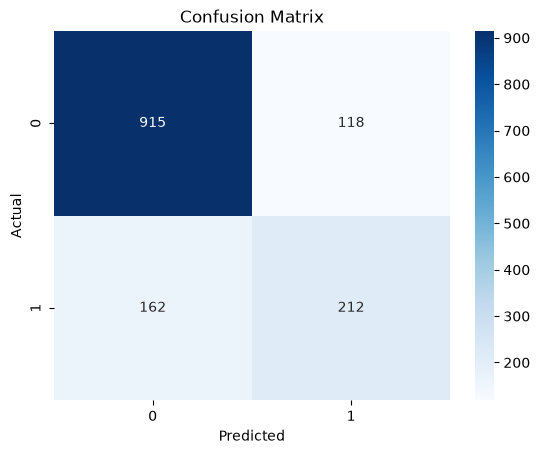

In [22]:
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [23]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,y_pred
))

              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1033
           1       0.64      0.57      0.60       374

    accuracy                           0.80      1407
   macro avg       0.75      0.73      0.73      1407
weighted avg       0.79      0.80      0.80      1407



In [24]:
from sklearn.metrics import roc_auc_score

y_prob=model.predict_proba(x_test)[:,1]

auc=roc_auc_score(
    y_test,
    y_prob
)

print("Roc-auc",auc)

Roc-auc 0.8362448297104638


In [25]:
new_customer = pd.DataFrame({
    "gender": ["Male"],
    "SeniorCitizen": [0],
    "Partner": ["Yes"],
    "Dependents": ["No"],
    "tenure": [5],
    "PhoneService": ["Yes"],
    "MultipleLines": ["No"],
    "InternetService": ["Fiber optic"],
    "OnlineSecurity": ["No"],
    "OnlineBackup": ["No"],
    "DeviceProtection": ["No"],
    "TechSupport": ["No"],
    "StreamingTV": ["Yes"],
    "StreamingMovies": ["Yes"],
    "Contract": ["Month-to-month"],
    "PaperlessBilling": ["Yes"],
    "PaymentMethod": ["Electronic check"],
    "MonthlyCharges": [95.5],
    "TotalCharges": [477.5]
})


churn_prob=model.predict_proba(new_customer)[0][1]

predict=model.predict(new_customer)[0]


print(f"{churn_prob:.2%}")
print(f"{predict}")

75.28%
1


In [26]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline



In [27]:
logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(
            max_iter=1000
        ))
    ]
)

logistic_model.fit(x_train, y_train)
logistic_pred = logistic_model.predict(x_test)

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [28]:
tree_model=Pipeline(
    steps=[
         ("preprocessor", preprocessor),
        ("classifier", DecisionTreeClassifier(
            random_state=42
        ))
    ]
)

tree_model.fit(x_train, y_train)
tree_pred = tree_model.predict(x_test)

In [29]:
forest_model=Pipeline(
    steps=[
         ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            random_state=42,
            max_depth=10
        ))
    ]
)

forest_model.fit(x_train, y_train)
forest_pred = forest_model.predict(x_test)

In [30]:
from sklearn.metrics import accuracy_score

logistic_pred = logistic_model.predict(x_test)

print(
    "Logistic Regression:",
    accuracy_score(y_test, logistic_pred)
)

print(
    "Decision Tree:",
    accuracy_score(y_test, tree_pred)
)

print(
    "Random Forest:",
    accuracy_score(y_test, forest_pred)
)

Logistic Regression: 0.8009950248756219
Decision Tree: 0.7221037668798863
Random Forest: 0.7924662402274343


                     Accuracy  Precision    Recall        F1   ROC-AUC
Logistic Regression  0.800995   0.642424  0.566845  0.602273  0.836245
Decision Tree        0.722104   0.478036  0.494652  0.486202  0.649792
Random Forest        0.792466   0.633987  0.518717  0.570588  0.830897


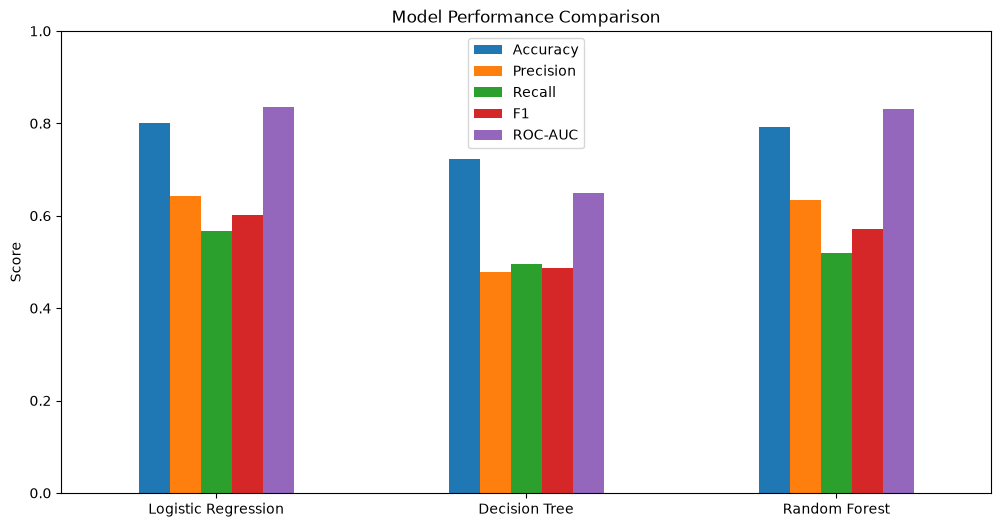

In [31]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

def evaluate_model(model,x_test,y_test):
    predictions=model.predict(x_test)
    prob=model.predict_proba(x_test)[0:,1]
    return {
        "Accuracy": accuracy_score(
            y_test,
            predictions
        ),
        "Precision": precision_score(
            y_test,
            predictions
        ),
        "Recall": recall_score(
            y_test,
            predictions
        ),
        "F1": f1_score(
            y_test,
            predictions
        ),
        "ROC-AUC": roc_auc_score(
            y_test,
            prob
        )
    }


results = {}

results["Logistic Regression"] = evaluate_model(
    logistic_model,
    x_test,
    y_test
)

results["Decision Tree"] = evaluate_model(
    tree_model,
    x_test,
    y_test
)

results["Random Forest"] = evaluate_model(
    forest_model,
    x_test,
    y_test
)

results_df = pd.DataFrame(results).T

print(results_df)


results_df.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.show()

In [32]:
rf=Pipeline(
    steps=[
         ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=100,
            random_state=42,
        ))
    ]
)

rf.fit(x_train, y_train)
forest_pred = rf.predict(x_test)


rf_results = evaluate_model(
    rf,
    x_test,
    y_test
)

print(rf_results)

{'Accuracy': 0.7924662402274343, 'Precision': 0.6375838926174496, 'Recall': 0.5080213903743316, 'F1': 0.5654761904761905, 'ROC-AUC': 0.8129701145617095}


In [33]:
from sklearn.model_selection import (StratifiedKFold,cross_val_score)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42

)

scores = cross_val_score(
    rf,
    x_train,
    y_train,
    cv=cv,
    scoring="roc_auc"
)

print("Scores:", scores)
print("Mean ROC-AUC:", scores.mean())
print("Std:", scores.std())

Scores: [0.82726522 0.81356135 0.81929879 0.82456453 0.83287714]
Mean ROC-AUC: 0.8235134062694858
Std: 0.006628227751044375


In [34]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "classifier__n_estimators": [100, 200, 300],
    "classifier__max_depth": [5, 10, 15, None],
    "classifier__min_samples_split": [2, 5, 10],
    "classifier__min_samples_leaf": [1, 2, 4]
}


grid_search=GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    cv=5,
    scoring="roc_auc",
    n_jobs=-1

)


grid_search.fit(x_train,y_train)

print(
    grid_search.best_params_
)

print(
    grid_search.best_score_
)

{'classifier__max_depth': 10, 'classifier__min_samples_leaf': 4, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 100}
0.8463534623077734


In [35]:
best_model = grid_search.best_estimator_

best_results = evaluate_model(
    best_model,
    x_test,
    y_test
)

print(best_results)

{'Accuracy': 0.7945984363894811, 'Precision': 0.6421404682274248, 'Recall': 0.5133689839572193, 'F1': 0.5705794947994056, 'ROC-AUC': 0.8339372887234627}


In [36]:
comparison = pd.DataFrame({
    "Baseline Random Forest": rf_results,
    "Tuned Random Forest": best_results
}).T

print(comparison)

                        Accuracy  Precision    Recall        F1   ROC-AUC
Baseline Random Forest  0.792466   0.637584  0.508021  0.565476  0.812970
Tuned Random Forest     0.794598   0.642140  0.513369  0.570579  0.833937


In [37]:
rf_balanced = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            random_state=42,
            class_weight="balanced"
        ))
    ]
)

rf_balanced.fit(
    x_train,
    y_train
)

balanced_results = evaluate_model(
    rf_balanced,
    x_test,
    y_test
)

print(balanced_results)

comparison = pd.DataFrame({
    "Baseline": rf_results,
    "Balanced": balanced_results,
    "Tuned": best_results
}).T

print(comparison)

{'Accuracy': 0.7611940298507462, 'Precision': 0.5431818181818182, 'Recall': 0.6390374331550802, 'F1': 0.5872235872235873, 'ROC-AUC': 0.8136858016990127}
          Accuracy  Precision    Recall        F1   ROC-AUC
Baseline  0.792466   0.637584  0.508021  0.565476  0.812970
Balanced  0.761194   0.543182  0.639037  0.587224  0.813686
Tuned     0.794598   0.642140  0.513369  0.570579  0.833937


In [38]:
rf_classifier = best_model.named_steps["classifier"]
preprocessor_fitted = best_model.named_steps["preprocessor"]

feature_names = preprocessor_fitted.get_feature_names_out()

print(feature_names)

['categorial__gender_Female' 'categorial__gender_Male'
 'categorial__Partner_No' 'categorial__Partner_Yes'
 'categorial__Dependents_No' 'categorial__Dependents_Yes'
 'categorial__PhoneService_No' 'categorial__PhoneService_Yes'
 'categorial__MultipleLines_No'
 'categorial__MultipleLines_No phone service'
 'categorial__MultipleLines_Yes' 'categorial__InternetService_DSL'
 'categorial__InternetService_Fiber optic'
 'categorial__InternetService_No' 'categorial__OnlineSecurity_No'
 'categorial__OnlineSecurity_No internet service'
 'categorial__OnlineSecurity_Yes' 'categorial__OnlineBackup_No'
 'categorial__OnlineBackup_No internet service'
 'categorial__OnlineBackup_Yes' 'categorial__DeviceProtection_No'
 'categorial__DeviceProtection_No internet service'
 'categorial__DeviceProtection_Yes' 'categorial__TechSupport_No'
 'categorial__TechSupport_No internet service'
 'categorial__TechSupport_Yes' 'categorial__StreamingTV_No'
 'categorial__StreamingTV_No internet service'
 'categorial__Stream

                                       Feature  Importance
42                           remainder__tenure    0.145181
44                     remainder__TotalCharges    0.122098
32         categorial__Contract_Month-to-month    0.097551
43                   remainder__MonthlyCharges    0.078575
14               categorial__OnlineSecurity_No    0.063741
12     categorial__InternetService_Fiber optic    0.052734
23                  categorial__TechSupport_No    0.045864
39  categorial__PaymentMethod_Electronic check    0.044837
34               categorial__Contract_Two year    0.038896
11             categorial__InternetService_DSL    0.021479
17                 categorial__OnlineBackup_No    0.021254
33               categorial__Contract_One year    0.017826
16              categorial__OnlineSecurity_Yes    0.015768
25                 categorial__TechSupport_Yes    0.013754
35             categorial__PaperlessBilling_No    0.012583


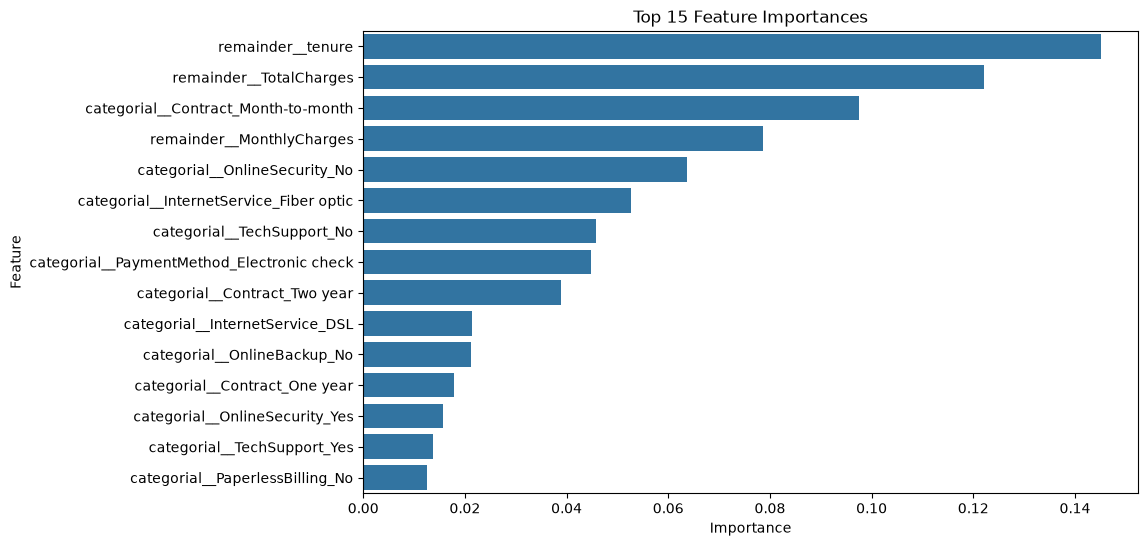

In [39]:
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_classifier.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)
print(
    importance_df.head(15)
)

top_features = importance_df.head(15)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Feature Importances")
plt.show()

In [40]:
customer = x_test.iloc[[0]]

print(customer)

actual = y_test.iloc[0]

print("Actual:", actual)

prediction = best_model.predict(customer)[0]

probability = best_model.predict_proba(customer)[0][1]

print("Prediction:", prediction)
print("Churn probability:", probability)

     gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
974  Female              0     Yes        Yes      59          Yes   

    MultipleLines InternetService OnlineSecurity OnlineBackup  \
974            No             DSL             No          Yes   

    DeviceProtection TechSupport StreamingTV StreamingMovies  Contract  \
974               No         Yes         Yes             Yes  Two year   

    PaperlessBilling            PaymentMethod  MonthlyCharges  TotalCharges  
974              Yes  Credit card (automatic)           75.95       4542.35  
Actual: 0
Prediction: 0
Churn probability: 0.01196252490195619


(5625, 45)
(1407, 45)


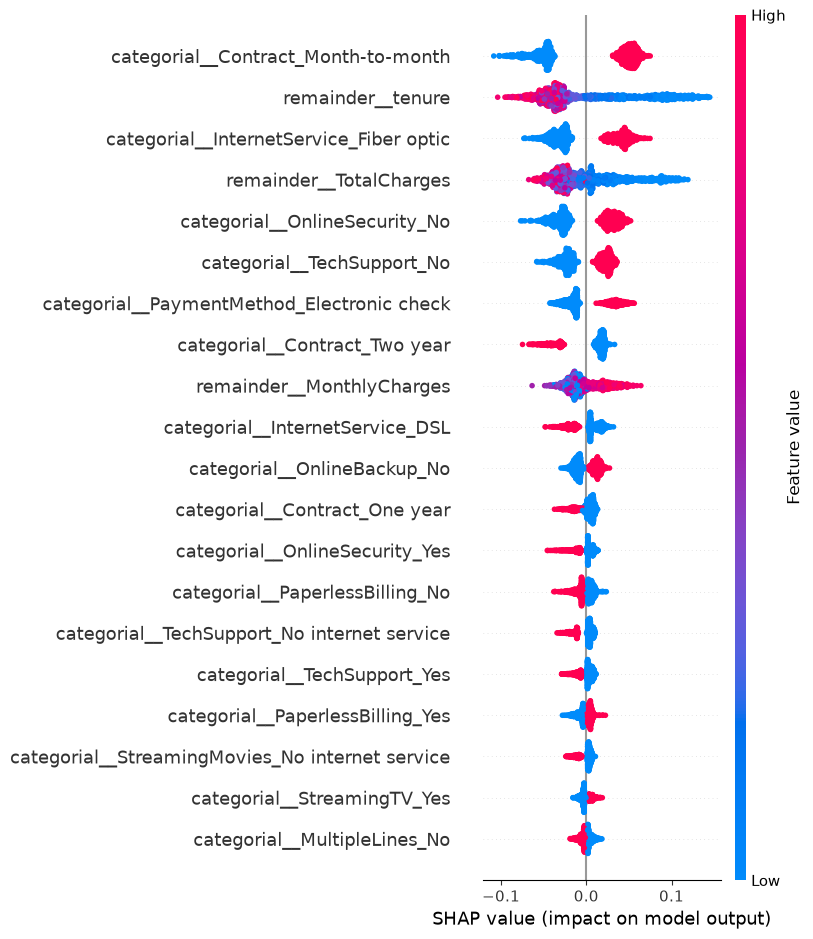

In [42]:
import shap

x_train_transformed = preprocessor_fitted.transform(
    x_train
)

x_test_transformed = preprocessor_fitted.transform(
    x_test
)

print(x_train_transformed.shape)
print(x_test_transformed.shape)

rf_classifier = best_model.named_steps["classifier"]

explainer = shap.TreeExplainer(
    rf_classifier
)

shap_values = explainer.shap_values(
    x_test_transformed
)

shap_values_churn = shap_values[:, :, 1]

shap.summary_plot(
    shap_values_churn,
    x_test_transformed,
    feature_names=feature_names
)



In [44]:
import joblib

joblib.dump(best_model,"../models/best_model.pkl")

['../models/best_model.pkl']

In [3]:
%%writefile .dockerignore
__pycache__
*.pyc
.ipynb_checkpoints
.git
.venv
venv
.env
notebooks
data

Overwriting .dockerignore
